In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 16.6 — The superflip

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and residuals and do not stop execution on a failed equality.

Equation (16.32), used graphically again in (17.17) and 19.6.6. Basis order is even, odd. The ordinary native `Swap` exchanges factors without a sign. To encode SMSA’s sign, a native box is supplied with the superflip tensor. Its four basis images expose the extra minus sign on odd–odd inputs. The box is deliberately labeled: drawing it as an ordinary crossing would conceal that extra data.

In [1]:
from discopy import symmetric, tensor
import numpy as np

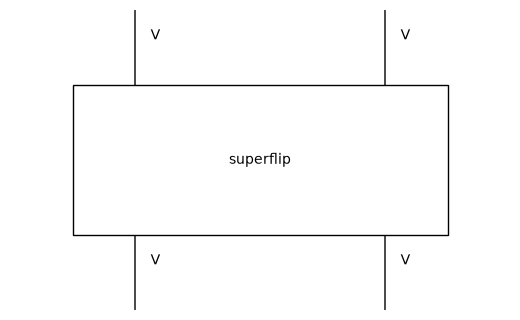

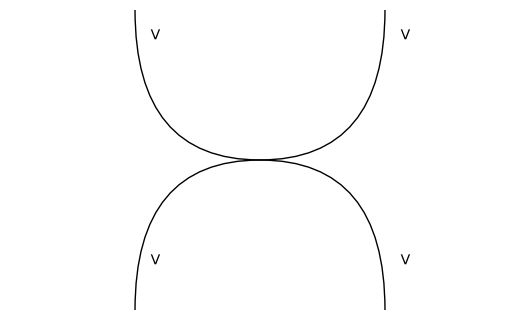

In [2]:
V = symmetric.Ty('V')
superflip = symmetric.Box('superflip', V @ V, V @ V)
ordinary = symmetric.Swap(V,V)
superflip.draw(figsize=(5,3))
ordinary.draw(figsize=(5,3))

In [3]:
data = np.array([(-1)**(i*j)*int(k==j and l==i) for i in range(2) for j in range(2) for k in range(2) for l in range(2)]).reshape(2,2,2,2)
F = tensor.Functor({V: tensor.Dim(2)}, {superflip:data}, dom=symmetric.Category, dtype=int)
print('(16.32): column matrix, basis even-even, even-odd, odd-even, odd-odd')
print(F(superflip).array.reshape(4,4).T)
print('ordinary flip =', F(ordinary >> symmetric.Id(V @ V)).array.reshape(4,4).T)
print('superflip squared minus identity =', (F(superflip >> superflip).array-F(symmetric.Id(V @ V)).array).reshape(4,4))
print('involutive =', F(superflip >> superflip) == F(symmetric.Id(V @ V)))

(16.32): column matrix, basis even-even, even-odd, odd-even, odd-odd
[[ 1  0  0  0]
 [ 0  0  1  0]
 [ 0  1  0  0]
 [ 0  0  0 -1]]
ordinary flip = [[1 0 0 0]
 [0 0 1 0]
 [0 1 0 0]
 [0 0 0 1]]
superflip squared minus identity = [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
involutive = True


Temporary placeholder: a native drawing with the exact signed-crossing convention of (17.17) has not been produced; the labeled box above is the executable linear map. General $\omega$-twisted crossings in (16.28) remain unconverted.